# 08_Final_Synthesis — Executive Summary & Actionable Insights

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
os.makedirs('output', exist_ok=True)
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp


In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 200)
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
metrics = pd.read_csv('reports/phase3c/metrics.csv')
gap = pd.read_csv('reports/phase3c/variant_gap.csv')
res = pd.read_csv('reports/phase5/routing_results.csv')
psr = pd.read_csv('reports/phase5/routing_per_service.csv')
imp = pd.read_csv('reports/phase5/business_impact.csv')
lock = json.load(open('reports/phase5/ROUTING_LOCK.json', encoding='utf-8'))
man = json.load(open('data/processed/MANIFEST.json', encoding='utf-8'))
ext = json.load(open('data/processed/MANIFEST_external.json', encoding='utf-8'))
print(f"2026 narratives: {man['all']['rows']:,} (train {man['train']['rows']:,} / val {man['val']['rows']:,} / test {man['test']['rows']:,})")
print(f"External 2025 narratives: {ext['rows']:,}")

2026 narratives: 106,307 (train 74,415 / val 15,945 / test 15,947)
External 2025 narratives: 251,388


## 1. Key Findings

In [4]:
print('\n=== CLASSIFIER (reference: company_masked) ===')
for _, r in metrics[metrics['variant'] == 'company_masked'].iterrows():
    print(f"{r['dataset']:<15} macro-F1 {r['macro_f1']:.3f} {r['macro_f1_ci95']} | accuracy {r['accuracy']:.3f} | top-2 {r['top2_accuracy']:.3f}")
print('\n=== AUTOMATIC ROUTING (threshold ' + str(lock['threshold']) + ') ===')
for _, r in res[res['dataset'] != 'val_2026'].iterrows():
    print(f"{r['dataset']:<15} coverage {100 * r['coverage']:.1f}% {r['coverage_ci95']} | precision {100 * r['precision_auto']:.1f}% {r['precision_ci95']}")
print('\n=== BRAND-NAME DEPENDENCY (lower bound) ===')
for _, r in gap.iterrows():
    print(f"{r['dataset']:<15} {100 * r['gap_as_is_minus_masked']:.2f} macro-F1 points {r['gap_ci95']}")


=== CLASSIFIER (reference: company_masked) ===
test_2026       macro-F1 0.828 [0.8219 ; 0.8346] | accuracy 0.839 | top-2 0.944
external_2025   macro-F1 0.842 [0.8408 ; 0.8438] | accuracy 0.844 | top-2 0.945

=== AUTOMATIC ROUTING (threshold 0.79) ===
test_2026       coverage 63.8% [0.6301 ; 0.6449] | precision 94.7% [0.9427 ; 0.9513]
external_2025   coverage 64.5% [0.6431 ; 0.6467] | precision 94.8% [0.9469 ; 0.9491]

=== BRAND-NAME DEPENDENCY (lower bound) ===
test_2026       1.52 macro-F1 points [0.0115 ; 0.0186]
external_2025   0.93 macro-F1 points [0.0085 ; 0.0101]


## 2. Executive Summary Dashboard

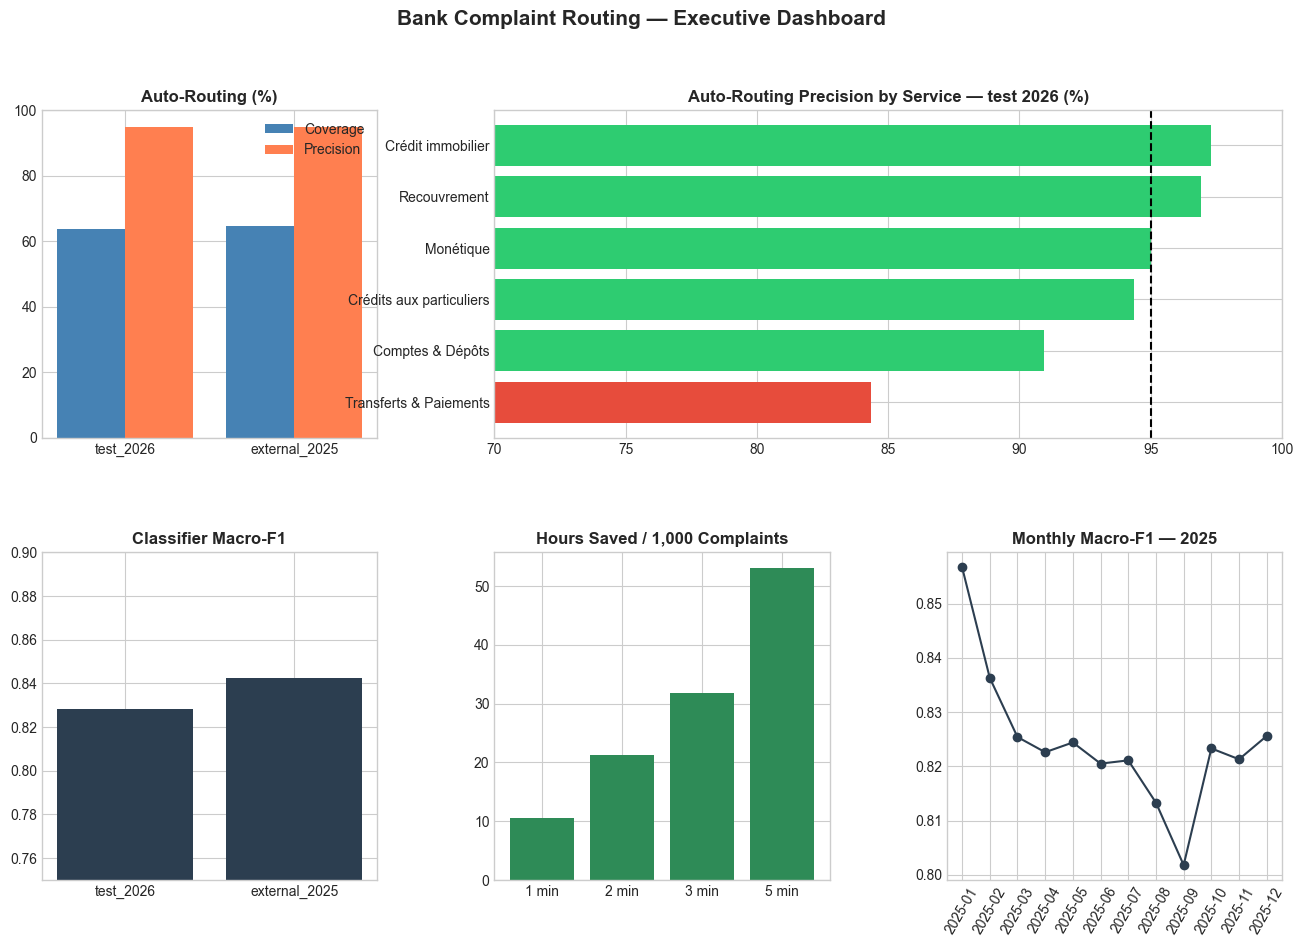

✓ Saved: 08_executive_dashboard.png


In [5]:
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.35)
ax1 = fig.add_subplot(gs[0, 0])
r = res[res['dataset'] != 'val_2026']
x = np.arange(len(r))
ax1.bar(x - 0.2, 100 * r['coverage'], 0.4, label='Coverage', color='steelblue')
ax1.bar(x + 0.2, 100 * r['precision_auto'], 0.4, label='Precision', color='coral')
ax1.set_xticks(x, r['dataset']); ax1.set_ylim(0, 100); ax1.legend(); ax1.set_title('Auto-Routing (%)', fontweight='bold')
ax2 = fig.add_subplot(gs[0, 1:])
t = psr[psr['dataset'] == 'test_2026'].set_index('service')['precision_auto_pred_as_service'].sort_values()
ax2.barh(t.index, 100 * t.values, color=['#e74c3c' if v < 0.9 else '#2ecc71' for v in t.values])
ax2.axvline(100 * lock['target_precision'], ls='--', color='black'); ax2.set_xlim(70, 100)
ax2.set_title('Auto-Routing Precision by Service — test 2026 (%)', fontweight='bold')
ax3 = fig.add_subplot(gs[1, 0])
m = metrics[metrics['variant'] == 'company_masked']
ax3.bar(m['dataset'], m['macro_f1'], color='#2c3e50'); ax3.set_ylim(0.75, 0.9)
ax3.set_title('Classifier Macro-F1', fontweight='bold')
ax4 = fig.add_subplot(gs[1, 1])
d = imp[imp['dataset'] == 'test_2026']
ax4.bar(d['triage_minutes_assumed'].astype(str) + ' min', d['triage_hours_saved_per_month'], color='seagreen')
ax4.set_title('Hours Saved / 1,000 Complaints', fontweight='bold')
ax5 = fig.add_subplot(gs[1, 2])
mm = pd.read_csv('reports/phase3c/monthly_macro_f1_external_2025_company_masked.csv')
ax5.plot(mm['received_month'], mm['macro_f1'], marker='o', color='#2c3e50'); ax5.tick_params(axis='x', rotation=60)
ax5.set_title('Monthly Macro-F1 — 2025', fontweight='bold')
fig.suptitle('Bank Complaint Routing — Executive Dashboard', fontsize=15, fontweight='bold')
plt.savefig('output/08_executive_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 08_executive_dashboard.png')

## 3. Recommendations for the Bank

In [6]:
recommendations = [
    ('Measure the current process first', 'Monthly volume, manual triage time and manual error rate are unknown: without them the real gain cannot be quantified.'),
    ('Retrain on French complaints', 'Results validate the method on US data; the model itself is not reusable as is.'),
    ('Pilot on the most reliable services', 'Debt collection and mortgage (96–97% precision); keep human review for Transfers & Payments and Accounts until per-service thresholds are validated.'),
    ('Log every automatic decision', 'Proposed service and confidence level, for Compliance traceability.'),
]
print('\n=== RECOMMENDATIONS ===')
for i, (title, text) in enumerate(recommendations, 1):
    print(f'\n{i}. {title}\n   {text}')


=== RECOMMENDATIONS ===

1. Measure the current process first
   Monthly volume, manual triage time and manual error rate are unknown: without them the real gain cannot be quantified.

2. Retrain on French complaints
   Results validate the method on US data; the model itself is not reusable as is.

3. Pilot on the most reliable services
   Debt collection and mortgage (96–97% precision); keep human review for Transfers & Payments and Accounts until per-service thresholds are validated.

4. Log every automatic decision
   Proposed service and confidence level, for Compliance traceability.


## 4. Data Quality & Limitations

In [7]:
limitations = [
    'English US corpus: the pipeline transfers to a French-speaking bank, not the model weights.',
    'Only narratives with consumer consent are published: sample not representative of all complaints.',
    'Target precision of 95% approached, not reached (94.7% test, 94.8% 2025): threshold set without safety margin.',
    'Precision uneven across services (Transfers & Payments 84% on test).',
    'Company masking incomplete (brands absent from the Company column remain).',
    'Labels = product chosen by the consumer: label noise not quantified (needs manual annotation).',
    'Business impact illustrative: volume and triage time are assumptions.',
    'DistilBERT (Phase 4) not done in this version.',
]
print('\n=== LIMITATIONS ===')
for l in limitations:
    print(f'  - {l}')


=== LIMITATIONS ===
  - English US corpus: the pipeline transfers to a French-speaking bank, not the model weights.
  - Only narratives with consumer consent are published: sample not representative of all complaints.
  - Target precision of 95% approached, not reached (94.7% test, 94.8% 2025): threshold set without safety margin.
  - Precision uneven across services (Transfers & Payments 84% on test).
  - Company masking incomplete (brands absent from the Company column remain).
  - Labels = product chosen by the consumer: label noise not quantified (needs manual annotation).
  - Business impact illustrative: volume and triage time are assumptions.
  - DistilBERT (Phase 4) not done in this version.
